[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ErvinasE/commit-message-generator/blob/main/1.4/cnn_FashionMNIST.ipynb)

# Konvoliucinis neuroninis tinklas (CNN): parduotuvės prekių nuotraukos

* **1 dalis**: CNN mokymas;
* **2 dalis**: filtrų ir požymių žemėlapių vizualizacija, konvoliucija ranka;
* **3 dalis**: palyginimas su paprastu tinklu (MLP).

Duomenys: Kaggle [Fashion-MNIST](https://www.kaggle.com/datasets/zalando-research/fashionmnist), „Zalando“ prekių nuotraukos, 28×28, nespalvotos, 10 klasių.
Naudojama 6 000 mokymo ir 1 000 testavimo nuotraukų. Colab'e rekomenduojama įjungti GPU.

---
# 1 DALIS

## Duomenys

CSV faile viena eilutė yra viena nuotrauka: `label` (klasė 0–9) ir 784 taškų šviesumai (0–255).
Atsitiktinai atrinkta po 600 mokymo ir 100 testavimo nuotraukų kiekvienai klasei.

| Nr. | Klasė (angl.) | Klasė |
|---|---|---|
| 0 | T-shirt/top | Marškinėliai |
| 1 | Trouser | Kelnės |
| 2 | Pullover | Megztinis |
| 3 | Dress | Suknelė |
| 4 | Coat | Paltas |
| 5 | Sandal | Sandalas |
| 6 | Shirt | Marškiniai |
| 7 | Sneaker | Sportbatis |
| 8 | Bag | Rankinė |
| 9 | Ankle boot | Aulinukas |

In [1]:
#@title Įkeliame CSV failus (Colab'e iš GitHub, lokaliai iš aplanko data/)

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers, models

keras.utils.set_random_seed(42)  # atkartojami rezultatai

GITHUB_BRANCH = 'main'
DATA_URL = f'https://raw.githubusercontent.com/ErvinasE/commit-message-generator/{GITHUB_BRANCH}/1.4/data/'
data_dir = 'data/' if os.path.exists('data/fashion-mnist_train.csv.gz') else DATA_URL

train_df = pd.read_csv(data_dir + 'fashion-mnist_train.csv.gz')
test_df = pd.read_csv(data_dir + 'fashion-mnist_test.csv.gz')
print('Mokymo lentelė:', train_df.shape, ' testavimo lentelė:', test_df.shape)
train_df.iloc[:5, :10]

Mokymo lentelė: (6000, 785)  testavimo lentelė: (1000, 785)


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9
0,8,0,0,0,0,0,0,0,0,0
1,2,0,0,0,0,0,0,0,0,18
2,4,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,5


Eilutę paverčiame 28×28×1 paveikslėliu.

In [2]:
#@title Iš lentelės į paveikslėlių masyvus

train_labels = train_df['label'].to_numpy().reshape(-1, 1)
train_images = train_df.drop(columns='label').to_numpy().reshape(-1, 28, 28, 1)
test_labels = test_df['label'].to_numpy().reshape(-1, 1)
test_images = test_df.drop(columns='label').to_numpy().reshape(-1, 28, 28, 1)

class_names = ['Marškinėliai', 'Kelnės', 'Megztinis', 'Suknelė', 'Paltas',
               'Sandalas', 'Marškiniai', 'Sportbatis', 'Rankinė', 'Aulinukas']

print('train_images:', train_images.shape, ' test_images:', test_images.shape)

train_images: (6000, 28, 28, 1)  test_images: (1000, 28, 28, 1)


In [3]:
#@title Normalizuojame taškų reikšmes iš 0–255 į 0–1

train_images, test_images = train_images / 255.0, test_images / 255.0

---
### Pirmosios 100 nuotraukų

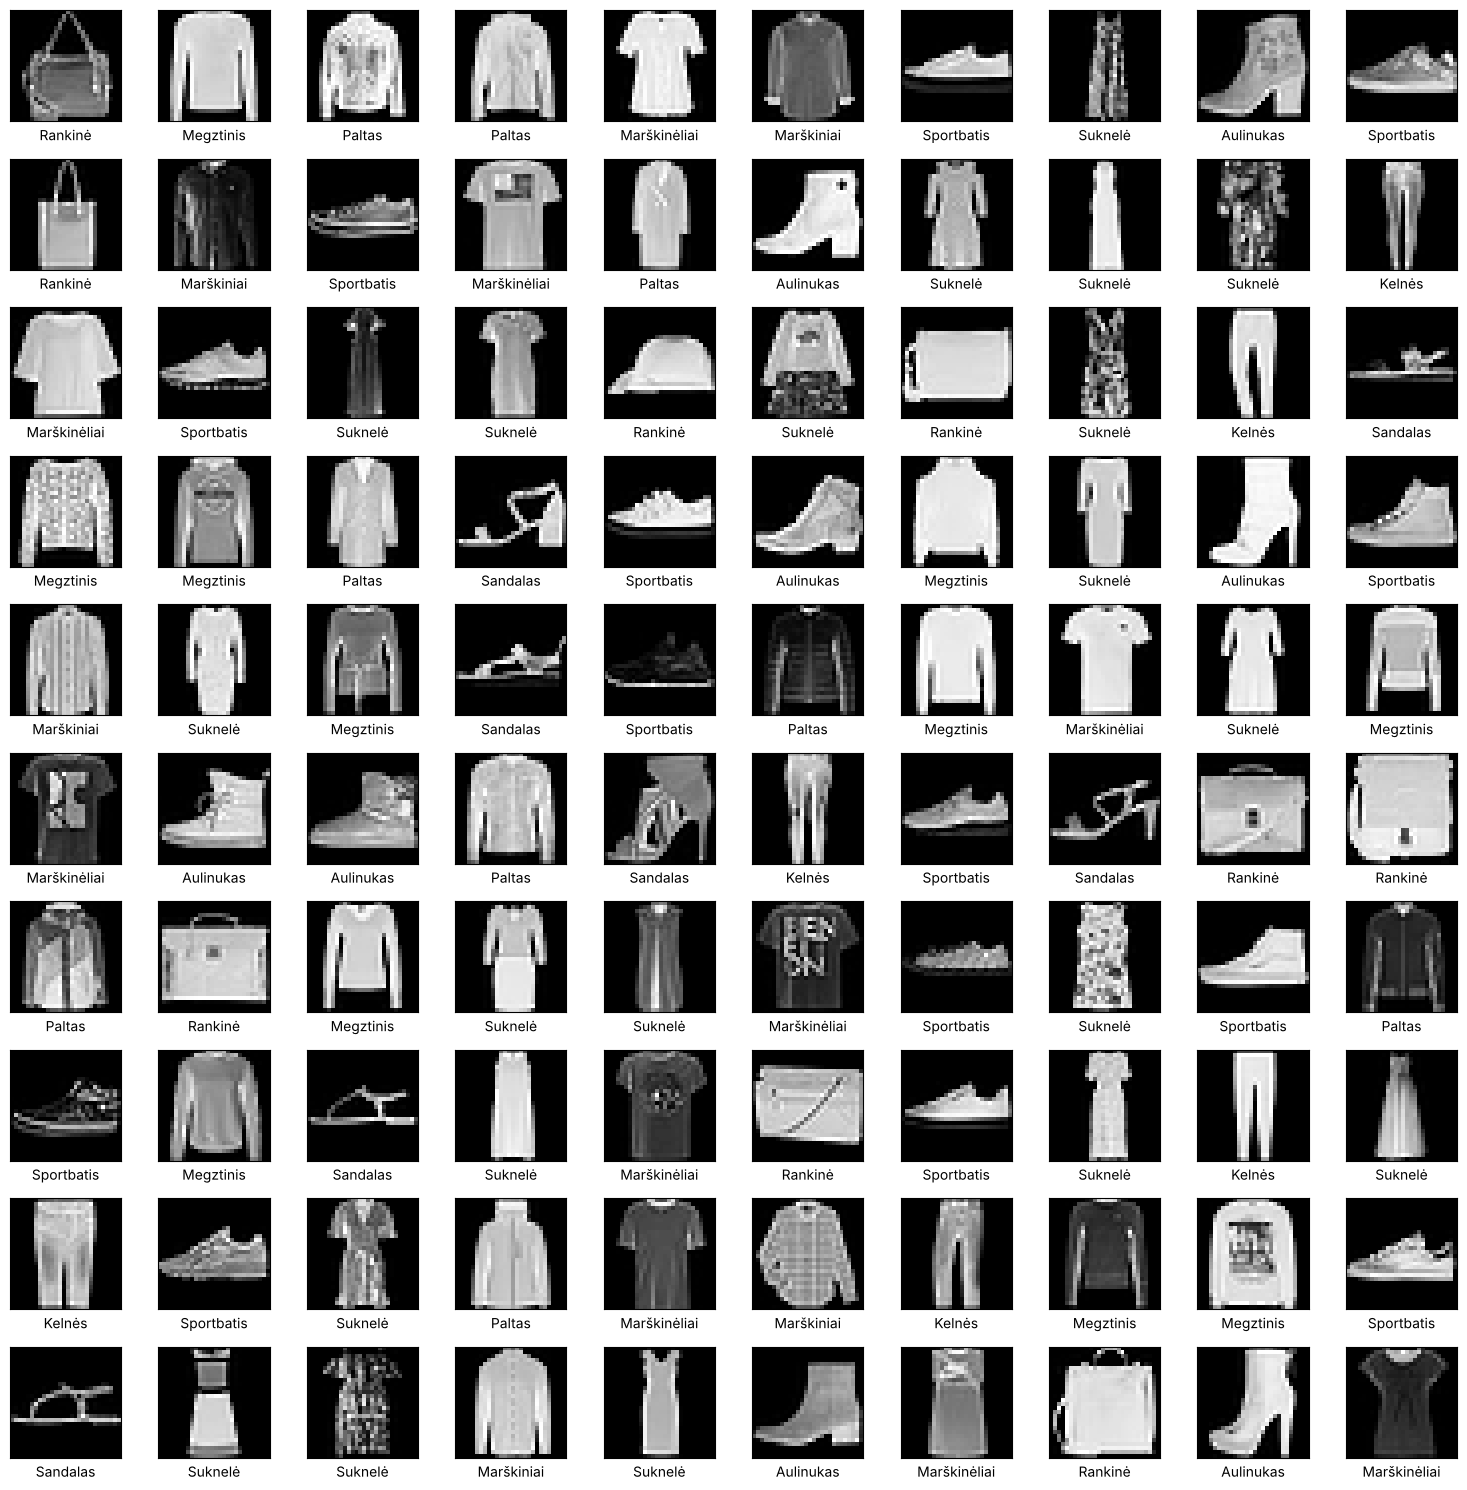

In [4]:
plt.figure(figsize=(15, 15))
for i in range(100):
    plt.subplot(10, 10, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i], cmap='gray')
    plt.xlabel(class_names[train_labels[i][0]])
plt.tight_layout()
plt.show()

# Konvoliucinis neuroninis tinklas

<img src="https://upload.wikimedia.org/wikipedia/commons/6/63/Typical_cnn.png" width=500 height=150>

---
### 2 žingsnis. Modelis

* `Conv2D(32, (3, 3))`: 32 filtrai 3×3. Filtras slenka per nuotrauką ir kiekvienoje vietoje skaičiuoja svertinę sumą, tada ReLU.
  Rezultatas yra požymių žemėlapis (28×28 → 26×26);
* `MaxPooling2D((2, 2))`: iš kiekvieno 2×2 kvadrato palieka didžiausią reikšmę, dydis sumažėja perpus;
* dar du `Conv2D`: sudėtingesni raštai;
* `Flatten`, `Dense(64)`, `Dense(10)`: klasifikatorius (10 klasių logitai).

In [5]:
model = models.Sequential()

model.add(layers.Input(shape=(28, 28, 1)))
model.add(layers.Conv2D(32, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))

model.add(layers.Flatten())
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(10))

`Conv2D` parametrų skaičius: (3·3·kanalai + 1)·filtrai, pvz. (3·3·1 + 1)·32 = 320.

In [6]:
model.compile(optimizer='adam', loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=['accuracy'])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 3, 3, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,322 (364.54 KB)

 Trainable params: 93,322 (364.54 KB)

 Non-trainable params: 0 (0.00 B)

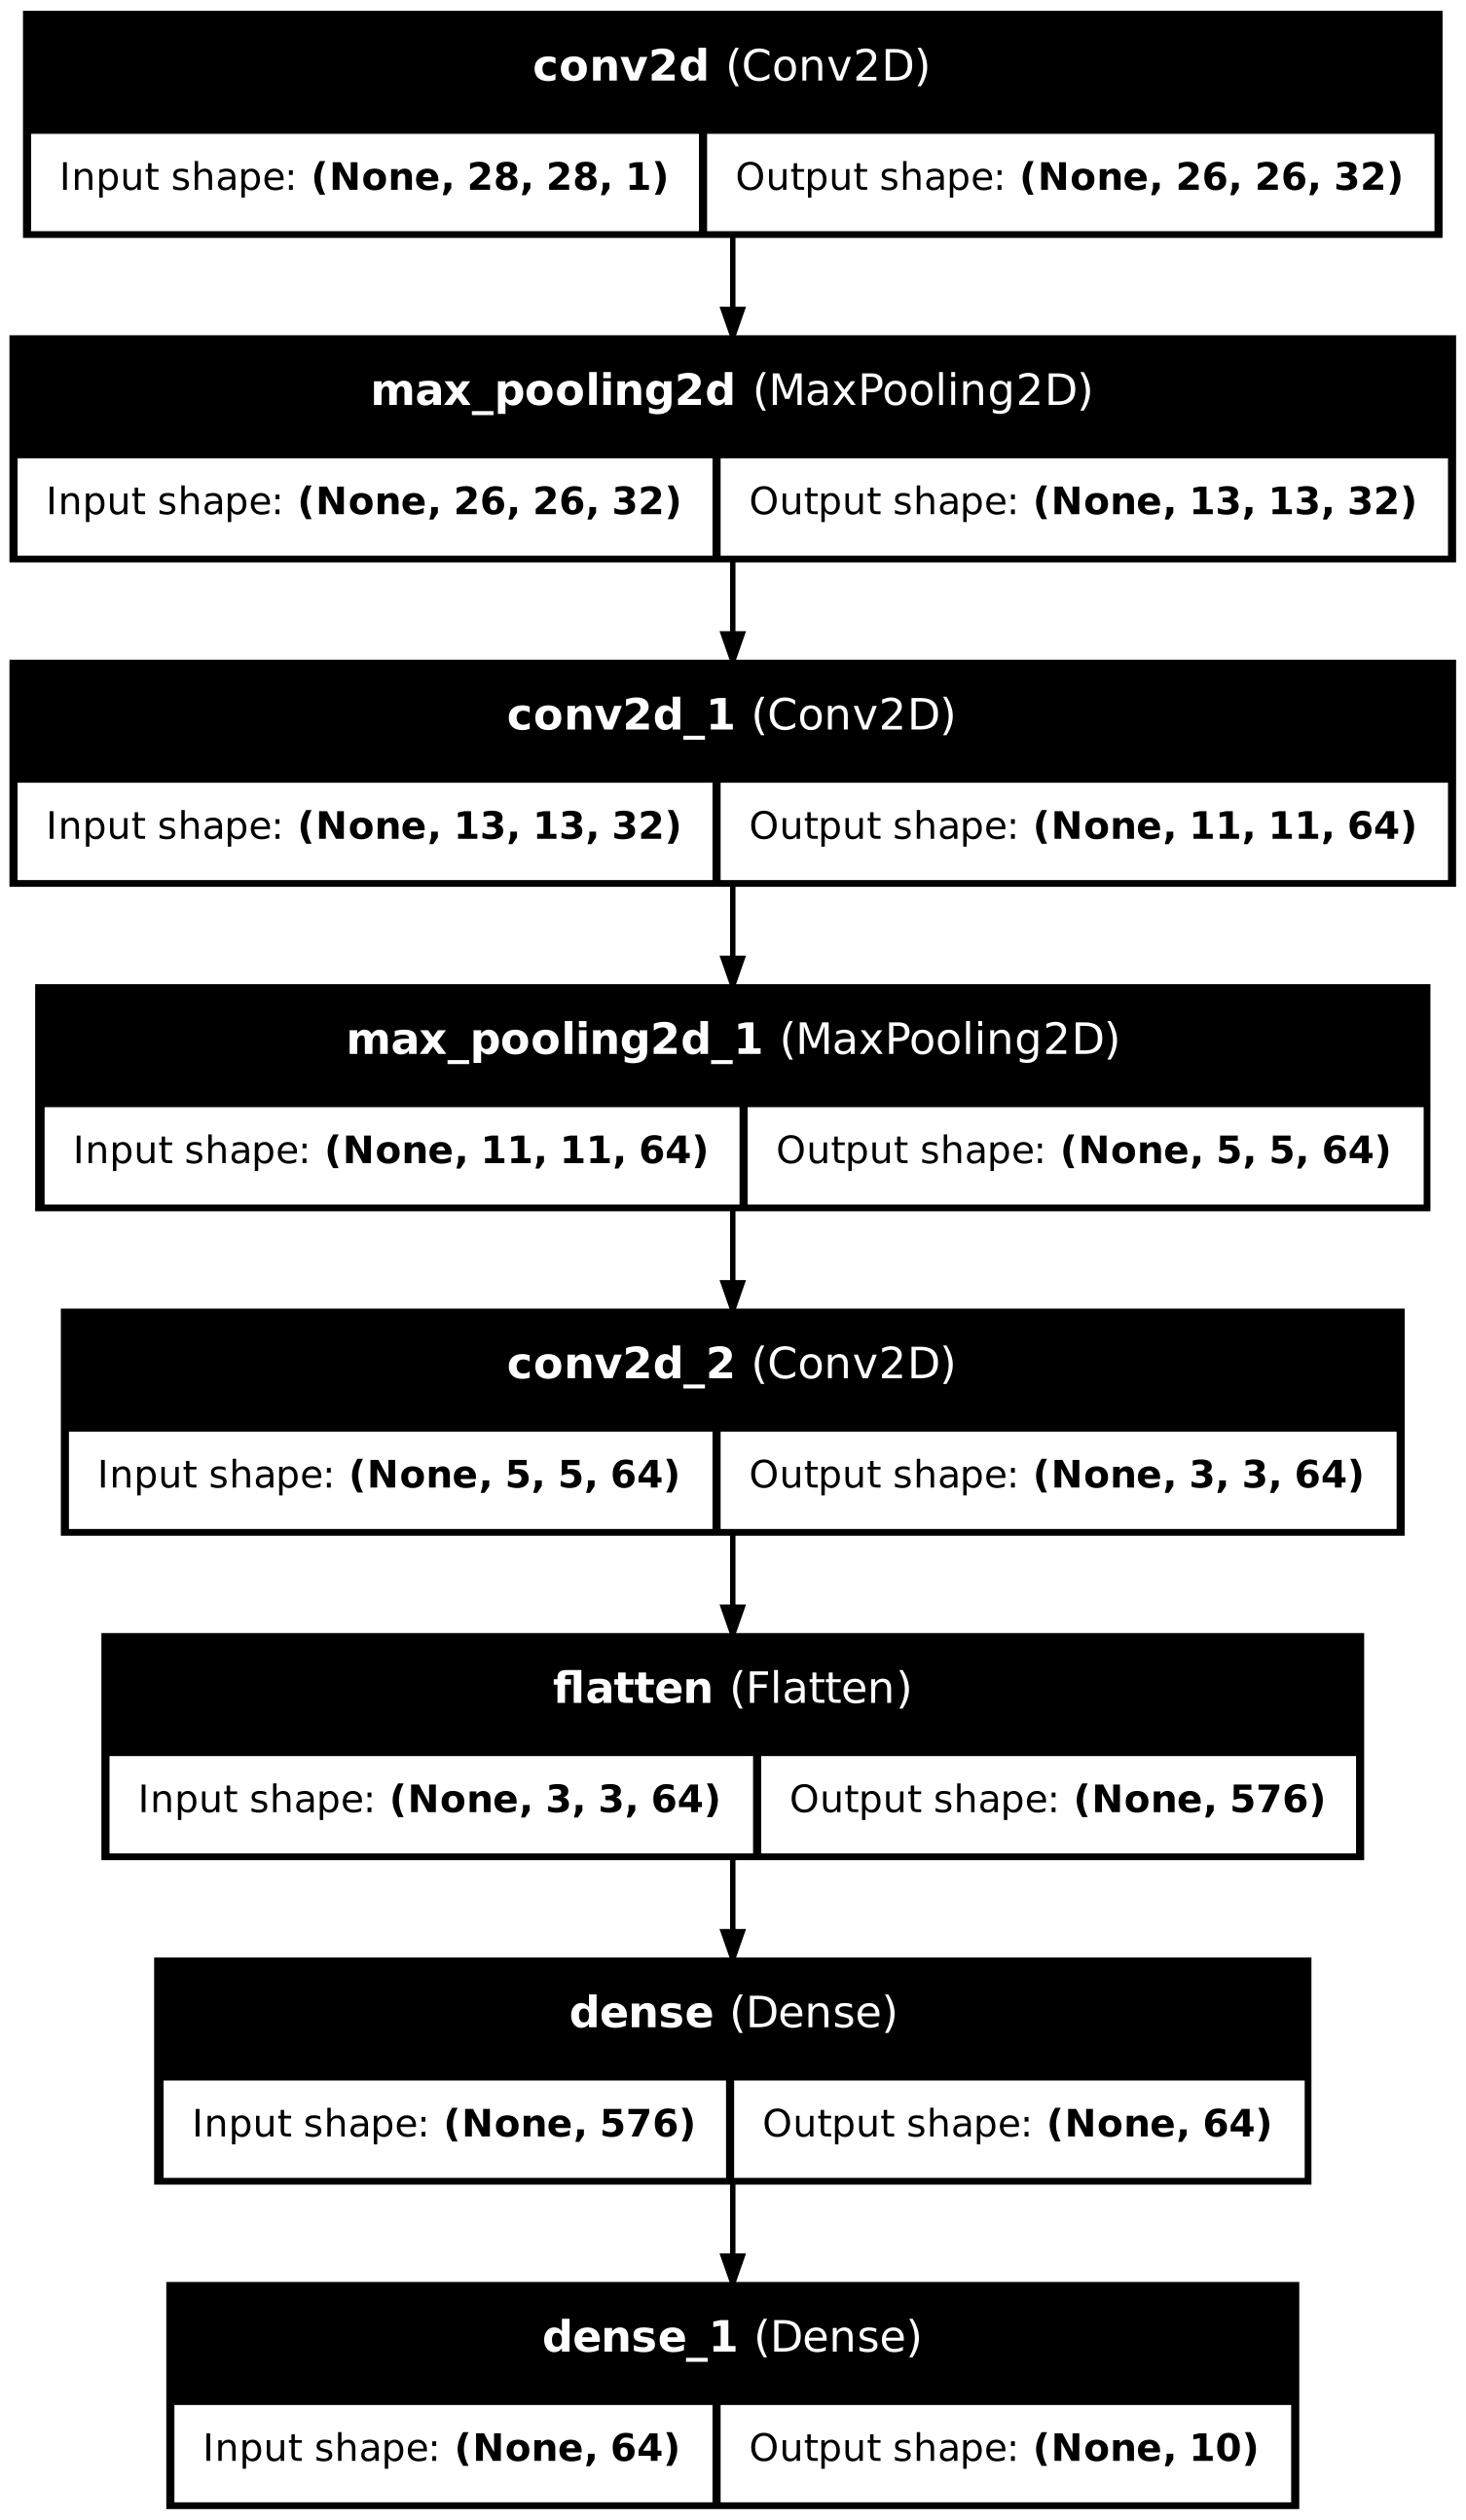

In [7]:
keras.utils.plot_model(model, to_file='model.png', show_shapes=True, show_layer_names=True)

---
### 3 žingsnis. Mokymas ir įvertinimas

10 % mokymo nuotraukų atidedame validavimui (`validation_split=0.1`).

In [8]:
history = model.fit(train_images, train_labels, epochs=20, validation_split=0.1)

Epoch 1/20


  1/169 ━━━━━━━━━━━━━━━━━━━━ 4:16 2s/step - accuracy: 0.0625 - loss: 2.3065

  5/169 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.1625 - loss: 2.2824

  9/169 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.2118 - loss: 2.2678

 14/169 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.2299 - loss: 2.2276

...

150/169 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9675 - loss: 0.0955

156/169 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9681 - loss: 0.0943

162/169 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9682 - loss: 0.0949

168/169 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9682 - loss: 0.0954

169/169 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9681 - loss: 0.0954 - val_accuracy: 0.8433 - val_loss: 0.5876


#### Įvertiname modelį

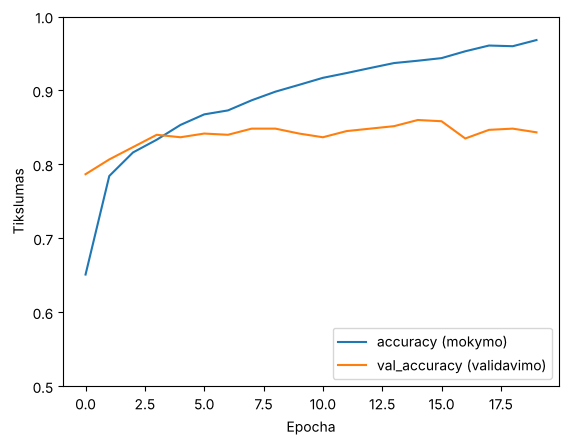

32/32 - 0s - 6ms/step - accuracy: 0.8520 - loss: 0.7040


0.8519999980926514


In [9]:
#@title Mokymo kreivė ir tikslumas su testavimo aibe

plt.plot(history.history['accuracy'], label='accuracy (mokymo)')
plt.plot(history.history['val_accuracy'], label='val_accuracy (validavimo)')
plt.xlabel('Epocha')
plt.ylabel('Tikslumas')
plt.ylim([0.5, 1])
plt.legend(loc='lower right')
plt.show()

test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=2)
cnn_test_acc = test_acc
print(test_acc)

Klaidų matrica (kiekvienos klasės testavimo aibėje yra po 100 nuotraukų):

In [10]:
pred = np.argmax(model.predict(test_images, verbose=0), axis=1)
cm = pd.crosstab(pd.Series([class_names[i] for i in test_labels[:, 0]], name='Tikrovė'),
                 pd.Series([class_names[i] for i in pred], name='Prognozė'))
cm.loc[class_names, class_names]

Prognozė,Marškinėliai,Kelnės,Megztinis,Suknelė,Paltas,Sandalas,Marškiniai,Sportbatis,Rankinė,Aulinukas
Tikrovė,,,,,,,,,,
Marškinėliai,83,0,1,2,0,0,11,0,3,0
Kelnės,1,92,0,3,1,0,2,0,1,0
Megztinis,2,0,77,1,2,0,16,0,2,0
Suknelė,1,0,2,90,1,0,6,0,0,0
Paltas,0,0,11,7,63,0,18,0,1,0
Sandalas,0,0,0,0,0,90,0,9,1,0
Marškiniai,12,0,9,4,0,0,72,0,3,0
Sportbatis,0,0,0,0,0,0,0,99,0,1
Rankinė,2,0,1,0,0,1,1,1,94,0


**Rezultatas:** testavimo tikslumas **85,2 %**.

* Persimokymas: mokymo tikslumas kyla iki 97 %, o validavimo nuo 8 epochos laikosi ~85 %, validavimo nuostolis kyla (0,41 → 0,59).
  Mokymo nuotraukų mažai (5 400).
* Lengviausi: sportbačiai (99 iš 100), rankinės (94). Sunkiausi: paltai (63) ir marškiniai (72), painiojami su megztiniais.

---
# 2 DALIS

## Filtrų ir požymių žemėlapių vizualizavimas

<img src="https://upload.wikimedia.org/wikipedia/commons/1/19/2D_Convolution_Animation.gif" width=200 height=200>

Pirmojo sluoksnio svorių forma `(3, 3, 1, 32)`: 32 filtrai 3×3, 1 kanalas.

filters: (3, 3, 1, 32)  biases: (32,)


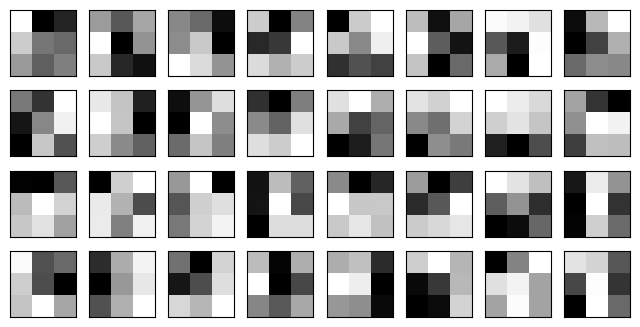

In [11]:
#@title Visi 32 pirmojo sluoksnio filtrai (šviesu = didelis svoris, tamsu = mažas/neigiamas)

filters, biases = model.layers[0].get_weights()
print('filters:', filters.shape, ' biases:', biases.shape)

plt.figure(figsize=(8, 4))
for i in range(32):
    ax = plt.subplot(4, 8, i + 1)
    ax.set_xticks([])
    ax.set_yticks([])
    plt.imshow(filters[:, :, 0, i], cmap='gray')
plt.show()

In [12]:
filters[:, :, 0, 2]   # 3-iojo filtro (indeksas 2) devyni svoriai

array([[ 0.00165142, -0.06143851, -0.24552274],
       [ 0.01083357,  0.13166884, -0.27313522],
       [ 0.24053954,  0.16735707,  0.0227326 ]], dtype=float32)

### Požymių žemėlapiai

`model_layers_0` grąžina pirmojo sluoksnio išėjimą: 32 žemėlapius vienai nuotraukai.

In [13]:
model_layers_0 = keras.Model(inputs=model.inputs, outputs=model.layers[0].output)

In [14]:
img = train_images[1]                  # viena nuotrauka
img = np.expand_dims(img, axis=0)      # pridedame paketo dimensiją: (1, 28, 28, 1)

feature_maps = model_layers_0.predict(img, verbose=0)
print('feature_maps:', feature_maps.shape, ' nuotrauka:', class_names[train_labels[1][0]])

feature_maps: (1, 26, 26, 32)  nuotrauka: Megztinis


Nuotraukos taškų reikšmės (0 = juoda, 1 = balta):

In [15]:
np.set_printoptions(linewidth=200)
for row in train_images[1][:, :, 0]:
    print(' '.join('{:0.2f}'.format(v) for v in row))

0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.07 0.45 0.75 0.77 0.64 0.57 0.60 0.70 0.86 0.78 0.44 0.07 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00
0.00 0.00 0.00 0.00 0.00 0.00 0.59 0.95 0.99 0.93 0.95 0.86 0.92 0.93 0.93 0.92 0.87 0.93 0.99 0.99 0.91 0.35 0.00 0.00 0.00 0.00 0.00 0.00
0.00 0.00 0.00 0.00 0.00 0.75 0.95 0.88 0.85 0.85 0.85 0.86 0.85 0.84 0.85 0.87 0.85 0.81 0.80 0.81 0.84 0.93 0.50 0.00 0.00 0.00 0.00 0.00
0.00 0.00 0.00 0.00 0.39 0.93 0.82 0.84 0.85 0.85 0.84 0.84 0.85 0.84 0.84 0.85 0.82 0.83 0.83 0.83 0.80 0.81 0.85 0.01 0.00 0.00 0.00 0.00
0.00 0.00 0.00 0.00 0.75 0.88 0.84 0.85 0.85 0.85 0.85 0.84 0.83 0.82 0.83 0.84 0.84 0.82 0.80 0.82 0.83 0.81 0.88 0.35 0.00 0.00 0.00 0.00
0.00 0.00 0.00 0.00 0.83 0.87 0.85 0.86 0.84 0.85 0.85 0.84 0.83 0.81 0.82 0.84 0.84 0.82 0.78 0.83 0.81 0.81 0.89 0.51 0.00 0.00 0.00 0.00
0.00 0.00 0.00 0.00 0.89 0.87 0.85 0.87 0.85 0.84 0.84 0.83 0.83 0.80 0.80 0.82 0.80 0.82 0.83 0.82 0.83 0.82 0.88 0.61 0.00 0.00 0.00 0.00
0.00 0.00 0.00 0.00 

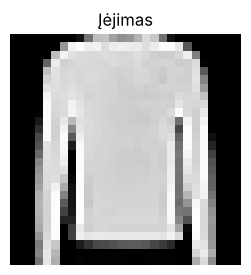

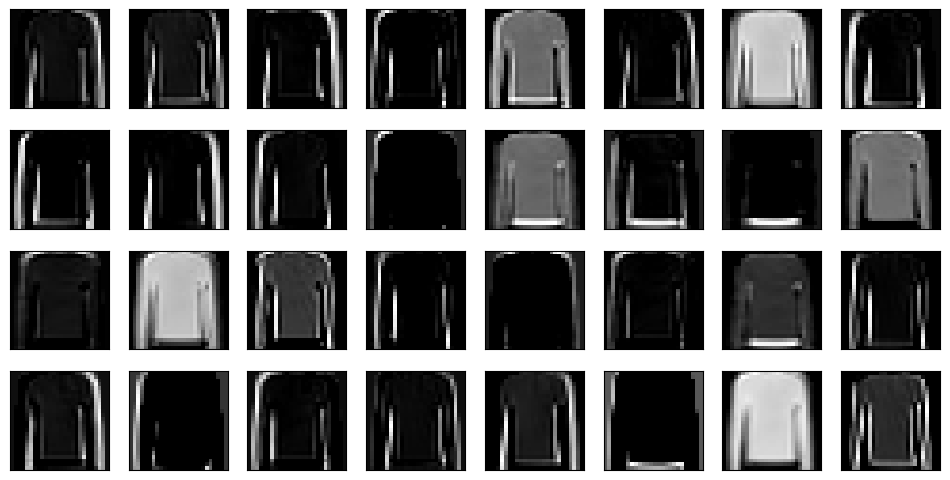

In [16]:
#@title 📍 Nuotrauka ir 32 jos požymių žemėlapiai po pirmojo sluoksnio

plt.figure(figsize=(3, 3))
plt.imshow(train_images[1][:, :, 0], cmap='gray')
plt.axis('off')
plt.title('Įėjimas')
plt.show()

plt.figure(figsize=(12, 6))
for i in range(32):
    ax = plt.subplot(4, 8, i + 1)
    ax.set_xticks([])
    ax.set_yticks([])
    plt.imshow(feature_maps[0, :, :, i], cmap='gray')
plt.show()

Vieni filtrai paryškina drabužio kraštus, kiti visą jo plotą.

### Konvoliucija ranka

3-iasis filtras perstumiamas per nuotrauką: kiekvienoje vietoje sudauginame ir susumuojame. Rezultatas 26×26.

filtro forma: (3, 3, 1)


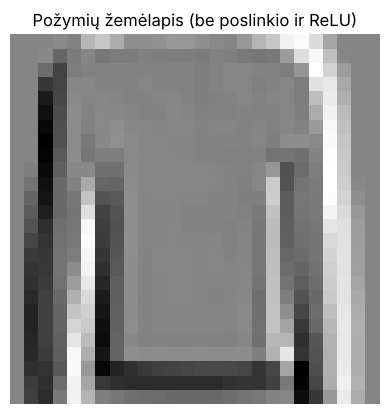

In [17]:
filter = filters[:, :, :, 2]
print('filtro forma:', filter.shape)

input_image = train_images[1]          # (28, 28, 1)

feature_map = np.zeros((input_image.shape[0] - filter.shape[0] + 1, input_image.shape[1] - filter.shape[1] + 1))

for i in range(feature_map.shape[0]):
    for j in range(feature_map.shape[1]):
        feature_map[i, j] = np.sum(input_image[i:i + filter.shape[0], j:j + filter.shape[1], :] * filter)

plt.imshow(feature_map, cmap='gray')
plt.title('Požymių žemėlapis (be poslinkio ir ReLU)')
plt.axis('off')
plt.show()

Pridedame poslinkį (*bias*) ir ReLU, kaip Keras:

bias = 0.0061527477


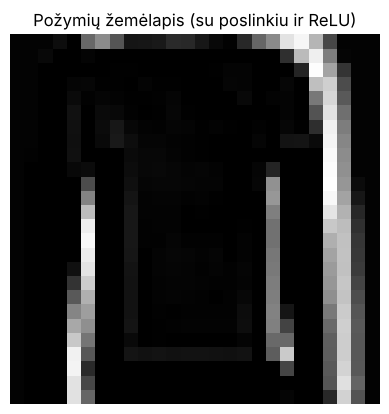

In [18]:
bias = biases[2]
print('bias =', bias)

feature_map = np.zeros((input_image.shape[0] - filter.shape[0] + 1, input_image.shape[1] - filter.shape[1] + 1))
for i in range(feature_map.shape[0]):
    for j in range(feature_map.shape[1]):
        feature_map[i, j] = np.sum(input_image[i:i + filter.shape[0], j:j + filter.shape[1], :] * filter) + bias

feature_map[feature_map < 0] = 0   # ReLU

plt.imshow(feature_map, cmap='gray')
plt.title('Požymių žemėlapis (su poslinkiu ir ReLU)')
plt.axis('off')
plt.show()

Palyginame su Keras rezultatu:

In [19]:
keras_map = feature_maps[0, :, :, 2]
print('Keras rezultatas (vidurys):')
print(np.round(keras_map[10:16, 10:16], 3))
print('Mūsų rezultatas (vidurys):')
print(np.round(feature_map[10:16, 10:16], 3))
print('Didžiausias skirtumas visame 26×26 žemėlapyje:', np.abs(keras_map - feature_map).max())

Keras rezultatas (vidurys):
[[0.011 0.011 0.01  0.008 0.008 0.   ]
 [0.008 0.008 0.005 0.006 0.002 0.   ]
 [0.006 0.005 0.    0.002 0.    0.   ]
 [0.006 0.007 0.    0.    0.    0.   ]
 [0.005 0.009 0.005 0.005 0.004 0.   ]
 [0.008 0.011 0.009 0.006 0.009 0.   ]]
Mūsų rezultatas (vidurys):
[[0.011 0.011 0.01  0.008 0.008 0.   ]
 [0.008 0.008 0.005 0.006 0.002 0.   ]
 [0.006 0.005 0.    0.002 0.    0.   ]
 [0.006 0.007 0.    0.    0.    0.   ]
 [0.005 0.009 0.005 0.005 0.004 0.   ]
 [0.008 0.011 0.009 0.006 0.009 0.   ]]
Didžiausias skirtumas visame 26×26 žemėlapyje: 3.732046947174661e-08


Skirtumas ~10⁻⁸, tik apvalinimo paklaida. Konvoliucinis sluoksnis daro tai, ką parašėme dviem `for` ciklais.

---
# 3 DALIS. Daugiasluoksnis perceptronas (MLP)

<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/4/46/Colored_neural_network.svg/250px-Colored_neural_network.svg.png" width=150 height=150>

---
### 2 žingsnis. Modelis

`Flatten` iškart ištiesina nuotrauką į 784 skaičius, todėl tinklas „nežino“, kurie taškai yra greta.

In [20]:
model = models.Sequential()
model.add(layers.Input(shape=(28, 28, 1)))
model.add(layers.Flatten())
model.add(layers.Dense(32, activation='relu'))
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(10))

model.compile(optimizer='adam', loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=['accuracy'])

In [21]:
#@title Modelio architektūra

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │        25,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,042 (125.16 KB)

 Trainable params: 32,042 (125.16 KB)

 Non-trainable params: 0 (0.00 B)

---
### 3 žingsnis. Mokymas ir įvertinimas

In [22]:
history = model.fit(train_images, train_labels, epochs=15, validation_split=0.1)

Epoch 1/15


  1/169 ━━━━━━━━━━━━━━━━━━━━ 2:40 957ms/step - accuracy: 0.1250 - loss: 2.3143

 24/169 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.3503 - loss: 1.9652    

 53/169 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4982 - loss: 1.4817

 76/169 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5452 - loss: 1.2999

...

 98/169 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9107 - loss: 0.2429

124/169 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9083 - loss: 0.2457

146/169 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9054 - loss: 0.2534

169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9006 - loss: 0.2639

169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9006 - loss: 0.2639 - val_accuracy: 0.7850 - val_loss: 0.6040


#### Įvertiname modelį

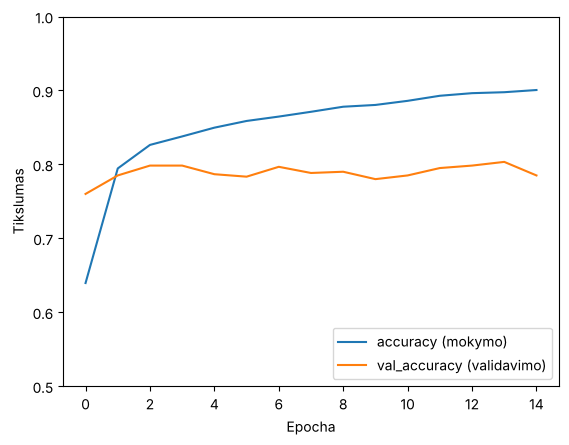

In [23]:
plt.plot(history.history['accuracy'], label='accuracy (mokymo)')
plt.plot(history.history['val_accuracy'], label='val_accuracy (validavimo)')
plt.xlabel('Epocha')
plt.ylabel('Tikslumas')
plt.ylim([0.5, 1])
plt.legend(loc='lower right')
plt.show()

In [24]:
test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=2)
print(test_acc)
print('CNN: {:.4f}   MLP: {:.4f}'.format(cnn_test_acc, test_acc))

32/32 - 0s - 3ms/step - accuracy: 0.8110 - loss: 0.5893


0.8109999895095825
CNN: 0.8520   MLP: 0.8110


---
# Išvados

| | CNN | MLP |
|---|---|---|
| Testavimo tikslumas | **85,2 %** | 81,1 % |
| Parametrų | 93 322 | 32 042 |
| Pirmojo sluoksnio parametrai | 320 | 25 120 |

* CNN tikslesnis ~4 punktais. Skirtumas nedidelis, nes Fashion-MNIST daiktas visada centre ir juodame fone.
* Konvoliucija taupi: tas pats 3×3 filtras naudojamas visose nuotraukos vietose.
* Abu modeliai persimoko, nes mokymo duomenų mažai.
* Ranka apskaičiuota konvoliucija sutapo su Keras.